# BurnInWatch — Exploratory Data Analysis & Data Quality

This notebook is the first **real EDA stage**.

Current evidence from the extraction stage:

- 68,769 steady-state records were extracted before removing all-missing records.
- 68,761 records remain after removing only rows where every engineering signal is missing.
- `ambientTemperature` is completely missing in the steady-state device-aging data.
- The other seven engineering fields are populated for roughly 99.8% of records overall.
- Device files have different lengths and timing gaps.
- `packageTemperature` and `supplyVoltage` show strong changes across the aging sequence.
- `collectorEmitterCurrent` is noisy and contains excursions/spikes.
- `heatSinkTemperature` and `internalTemperature` have unusual numerical scales that must be investigated from the experiment documentation before treating them as physical temperatures.

**Important:** We will not silently "fix" unusual values. This notebook measures and visualizes them so we can make evidence-based preprocessing decisions.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

DATA_ROOT = Path("dataset/Data").resolve()
PROCESSED = Path("processed")
PROCESSED.mkdir(exist_ok=True)

AGING_CSV = PROCESSED / "burninwatch_aging_canonical_v1.csv"

aging = pd.read_csv(AGING_CSV)

print("Shape:", aging.shape)
print("Columns:", aging.columns.tolist())
display(aging.head())

Shape: (68761, 15)
Columns: ['device_id', 'file_name', 'file_role', 'event_index', 'date', 'timeEpoch', 'supplyVoltage', 'node1Voltage', 'node2Voltage', 'collectorEmitterCurrent', 'heatSinkTemperature', 'packageTemperature', 'internalTemperature', 'ambientTemperature', 'measurement_valid']


,device_id,file_name,file_role,event_index,date,timeEpoch,supplyVoltage,node1Voltage,node2Voltage,collectorEmitterCurrent,heatSinkTemperature,packageTemperature,internalTemperature,ambientTemperature,measurement_valid
0,Device_2,Device2 1.mat,main,1,12/24/2008 9:59:48 AM,3.312986e+09,2.447730,2.443165,1.910721,0.157385,718.797002,30.404121,-2254.045786,NaN,True
1,Device_2,Device2 1.mat,main,2,12/24/2008 9:59:48 AM,3.312986e+09,2.443545,2.450073,1.737816,0.083021,718.801617,30.145092,-2254.266875,NaN,True
2,Device_2,Device2 1.mat,main,3,12/24/2008 9:59:48 AM,3.312986e+09,2.461683,2.456981,2.013080,0.087395,718.801617,30.080334,-2254.266875,NaN,True
3,Device_2,Device2 1.mat,main,4,12/24/2008 9:59:48 AM,3.312986e+09,2.461683,2.443165,2.043511,0.174882,718.797002,30.209849,-2254.045786,NaN,True
4,Device_2,Device2 1.mat,main,5,12/24/2008 9:59:48 AM,3.312986e+09,2.456102,2.452836,1.824960,0.085208,718.801617,30.371743,-2254.156325,NaN,True


## 1. Missingness and data-quality profile

We separate:
- structural missingness (for example, a signal that is absent for the entire experiment)
- occasional missing observations
- rows where all engineering signals are missing

In [2]:
ENGINEERING_FIELDS = [
    "supplyVoltage",
    "node1Voltage",
    "node2Voltage",
    "collectorEmitterCurrent",
    "heatSinkTemperature",
    "packageTemperature",
    "internalTemperature",
    "ambientTemperature",
]

missing_summary = pd.DataFrame({
    "missing_count": aging[ENGINEERING_FIELDS].isna().sum(),
    "missing_fraction": aging[ENGINEERING_FIELDS].isna().mean(),
    "unique_values": aging[ENGINEERING_FIELDS].nunique(dropna=True)
}).sort_values("missing_fraction", ascending=False)

display(missing_summary)

,missing_count,missing_fraction,unique_values
ambientTemperature,68761,1.0,0
supplyVoltage,0,0.0,516
node2Voltage,0,0.0,2573
node1Voltage,0,0.0,524
collectorEmitterCurrent,0,0.0,351
heatSinkTemperature,0,0.0,112
packageTemperature,0,0.0,11116
internalTemperature,0,0.0,84


In [4]:
# Rows with partial missingness
partial_missing = (
    aging[ENGINEERING_FIELDS].isna().sum(axis=1)
)

print("Rows with no engineering values:",
      int((partial_missing == len(ENGINEERING_FIELDS)).sum()))

print("Rows with at least one missing engineering value:",
      int((partial_missing > 0).sum()))

print("\nDistribution of number of missing fields per row:")
display(partial_missing.value_counts().sort_index())

Rows with no engineering values: 0
Rows with at least one missing engineering value: 68761

Distribution of number of missing fields per row:


1    68761
Name: count, dtype: int64

## 2. Descriptive statistics by device and file

We need to understand whether the devices have different operating ranges.

This is especially important for an unsupervised model because a large difference between devices can be either:
- useful degradation information,
- normal operating-condition variation,
- or a nuisance effect that needs normalization.

In [5]:
summary_by_file = (
    aging
    .groupby(["device_id", "file_name", "file_role"])
    [ENGINEERING_FIELDS[:-1]]
    .agg(["count", "mean", "std", "min", "median", "max"])
)

display(summary_by_file)
summary_by_file.to_csv(PROCESSED / "eda_summary_by_file.csv")

supplyVoltage                                                   node1Voltage                                                   node2Voltage            \
                                                count      mean       std       min    median       max        count      mean       std       min    median       max        count      mean   
device_id file_name           file_role                                                                                                                                                         
Device_2  Device2  1.mat      main              10977  4.724532  0.937927  2.439359  5.415414  5.448900        10977  4.722203  0.937914  2.437638  5.413639  5.442653        10977  4.390532   
          Device2b  1.mat     b                  6434  4.764506  1.123855  2.442149  5.414019  5.938631         6434  4.762269  1.123582  2.444546  5.412258  5.937272         6434  4.440331   
          Device2check  1.mat check               116  2.450256  0.003972  2.411454  2.450521  2.454706          116  2.444904  0.003874  2.407243  2.445237  2.448691          116  1.602652   
Device_3  Device3  1.mat      main               9836  4.660813  1.259632  2.430987  5.418205  5.956769         9836  4.658450  1.259316  2.437638  5.415021  5.952470         9836  4.331480   
          Device3b  1.mat     b                  5238  4.245228  1.070102  2.437964  4.437348  5.945607         5238  4.242840  1.069742  2.443165  4.435455  5.942799         5238  3.913103   
          Device3check  1.mat check               112  2.443644  0.031460  2.114267  2.446335  2.451916          112  2.436540  0.031030  2.111577  2.439020  2.444546          112  1.332058   
Device_4  Device4  1.mat      main              10770  4.494198  0.990161  2.411454  4.929869  5.476805        10770  4.491826  0.990139  2.398953  4.925929  5.461996        10770  4.162476   
          Device4b  1.mat     b                 14607  5.078078  0.842648  2.415640  5.425181  5.945607        14607  5.075625  0.842501  2.440402  5.421929  5.941417        14607  4.737276   
Device_5  Device5  1.mat      main              10510  4.713029  1.223611  2.443545  4.936846  5.959560        10510  4.710712  1.223645  2.437638  4.935600  5.957996        10510  4.389683   
          Device5check  1.mat check               161  2.461925  0.001320  2.457497  2.461683  2.464473          161  2.461598  0.001037  2.459744  2.461126  2.465271          161  2.454161   

                                                                                collectorEmitterCurrent                                                   heatSinkTemperature                        \
                                              std       min    median       max                   count      mean       std       min    median       max               count        mean       std   
device_id file_name           file_role                                                                                                                                                               
Device_2  Device2  1.mat      main       0.964469  1.737816  4.933096  5.435212                   10977  0.107798  0.036707 -0.220997  0.089582  0.450467               10977  718.953336  0.097172   
          Device2b  1.mat     b          1.116732  1.473617  4.935863  5.929028                    6434  0.106338  0.036234 -0.179441  0.089582  0.393600                6434  719.171993  0.024465   
          Device2check  1.mat check      0.020246  1.560761  1.598109  1.661738                     116  0.136418  0.007772  0.120203  0.134420  0.159572                 116  719.172955  0.004306   
Device_3  Device3  1.mat      main       1.251708  1.726750  4.940013  5.930412                    9836  0.107370  0.038073 -0.389410  0.091770  0.605757                9836  719.219942  0.032224   
          Device3b  1.mat     b          1.050692  1.223251  4.087246  5.646848                    5238  0.106228  0.040816 -0.336918  0.

## 3. Create relative elapsed time

`timeEpoch` is an absolute epoch-like quantity. For analysis we create:

`elapsed_seconds`

relative to the first recorded event of each device.

We keep the original `timeEpoch` unchanged.

In [6]:
aging["timeEpoch"] = pd.to_numeric(aging["timeEpoch"], errors="coerce")

aging = aging.sort_values(
    ["device_id", "timeEpoch", "file_name", "event_index"]
).reset_index(drop=True)

aging["elapsed_seconds"] = (
    aging.groupby("device_id")["timeEpoch"]
    .transform(lambda s: s - s.min())
)

aging["elapsed_hours"] = aging["elapsed_seconds"] / 3600.0

display(
    aging.groupby("device_id")
    .agg(
        records=("event_index", "size"),
        duration_hours=("elapsed_hours", "max"),
        first_epoch=("timeEpoch", "min"),
        last_epoch=("timeEpoch", "max")
    )
    .reset_index()
)

,device_id,records,duration_hours,first_epoch,last_epoch
0,Device_2,17527,6.230248,3.312986e+09,3.313009e+09
1,Device_3,15186,1.055541,3.313005e+09,3.313008e+09
2,Device_4,25377,1.847117,3.313009e+09,3.313016e+09
3,Device_5,10671,3.975537,3.312994e+09,3.313009e+09


In [7]:
# ============================================================
# 4. GAP ANALYSIS
# ============================================================

aging["dt_seconds"] = (
    aging.groupby("device_id")["timeEpoch"].diff()
)

gap_summary = (
    aging.assign(
        large_gap=lambda d: d["dt_seconds"] > 10
    )
    .groupby("device_id")
    .agg(
        median_dt=("dt_seconds", "median"),
        mean_dt=("dt_seconds", "mean"),
        max_dt=("dt_seconds", "max"),
        gaps_over_10s=("large_gap", "sum"),
    )
    .reset_index()
)

display(gap_summary)

print("\nLargest gaps:")
display(
    aging.nlargest(30, "dt_seconds")[
        ["device_id", "file_name", "event_index",
         "timeEpoch", "dt_seconds"]
    ]
)

,device_id,median_dt,mean_dt,max_dt,gaps_over_10s
0,Device_2,0.2,1.279750,18240.662598,3
1,Device_3,0.2,0.250244,267.493000,2
2,Device_4,0.2,0.262044,838.457000,1
3,Device_5,0.2,1.341325,11888.024590,1



Largest gaps:


,device_id,file_name,event_index,timeEpoch,dt_seconds
17411,Device_2,Device2check 1.mat,0,3.313009e+09,18240.662598
68600,Device_5,Device5check 1.mat,1,3.313009e+09,11888.024590
43483,Device_4,Device4b 1.mat,1,3.313012e+09,838.457000
32601,Device_3,Device3check 1.mat,1,3.313008e+09,267.493000
10977,Device_2,Device2b 1.mat,1,3.312989e+09,164.801000
27363,Device_3,Device3b 1.mat,0,3.313007e+09,41.290000
11276,Device_2,Device2b 1.mat,300,3.312989e+09,24.199000
17511,Device_2,Device2check 1.mat,100,3.313009e+09,3.552000
68649,Device_5,Device5check 1.mat,50,3.313009e+09,1.119000
58199,Device_5,Device5 1.mat,110,3.312994e+09,1.024000


## 5. Signal distributions

We inspect distributions before deciding scaling, clipping, transformations, or feature removal.

No values are clipped here.

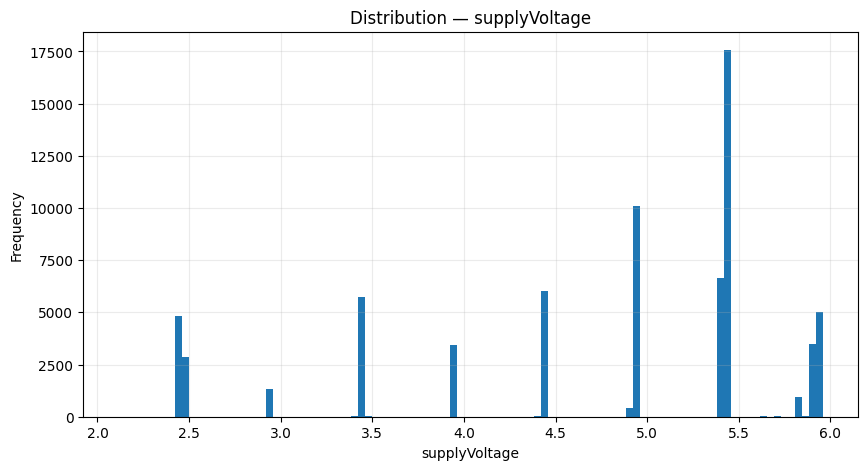

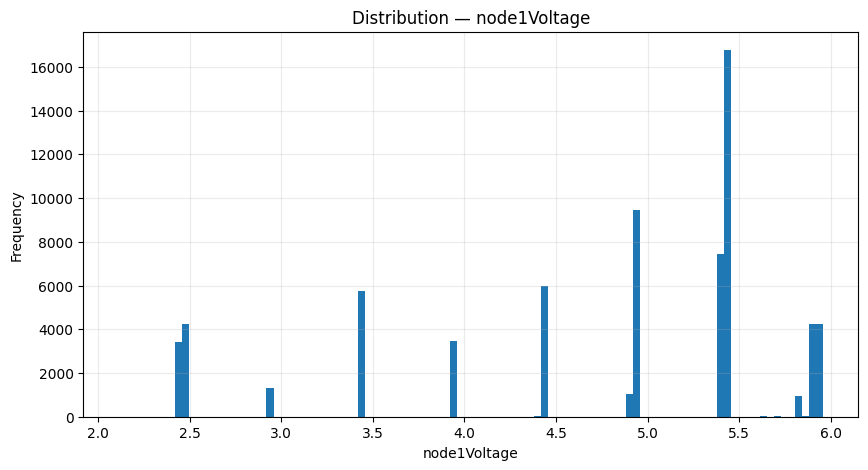

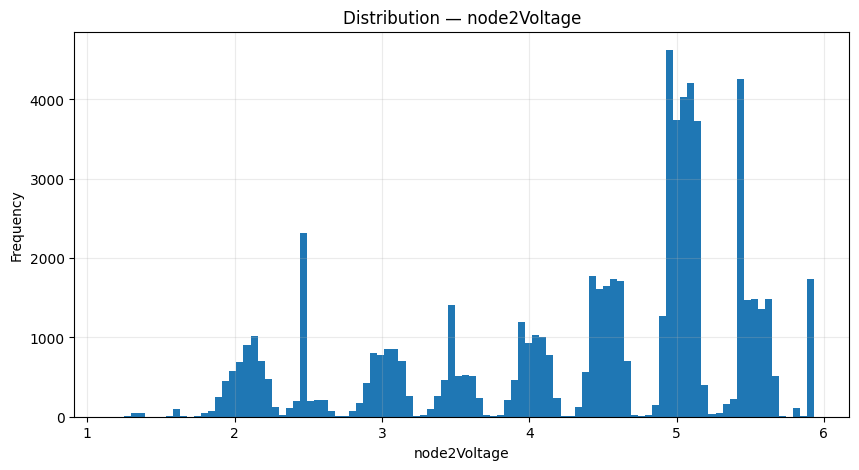

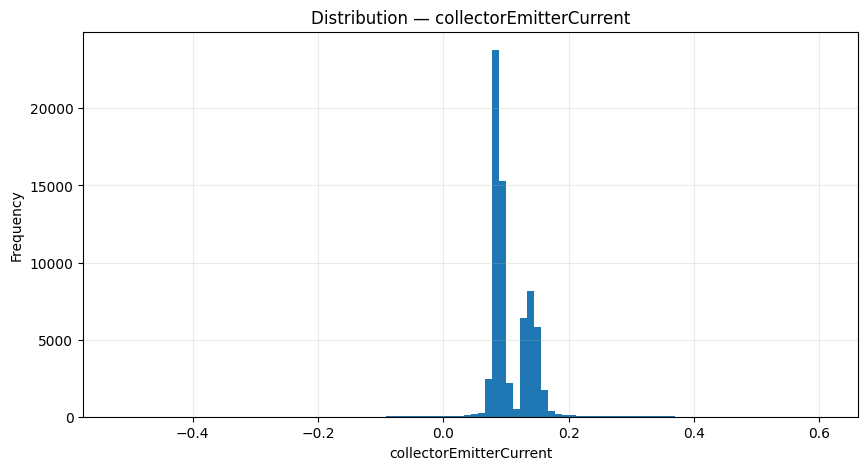

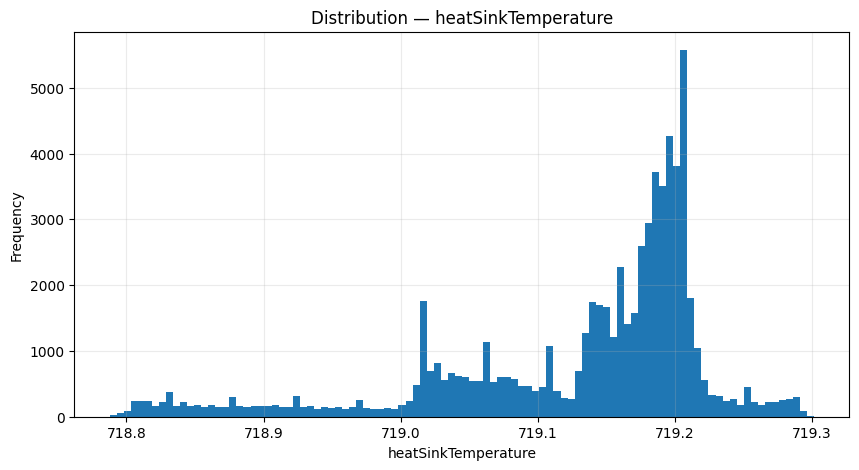

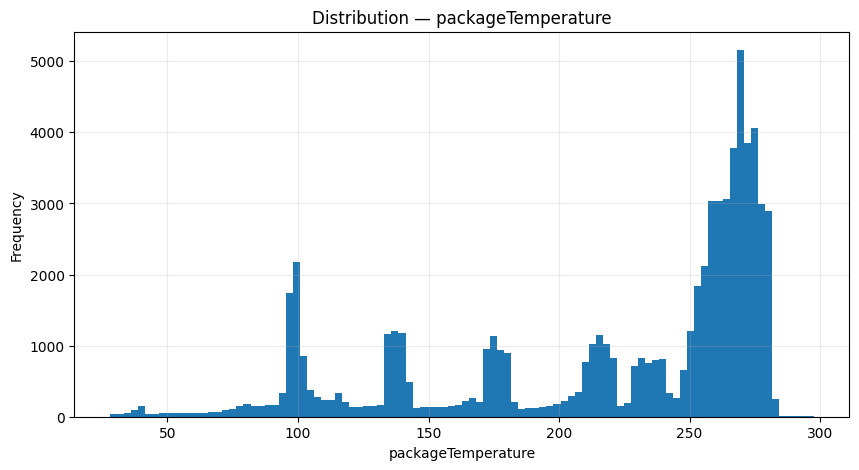

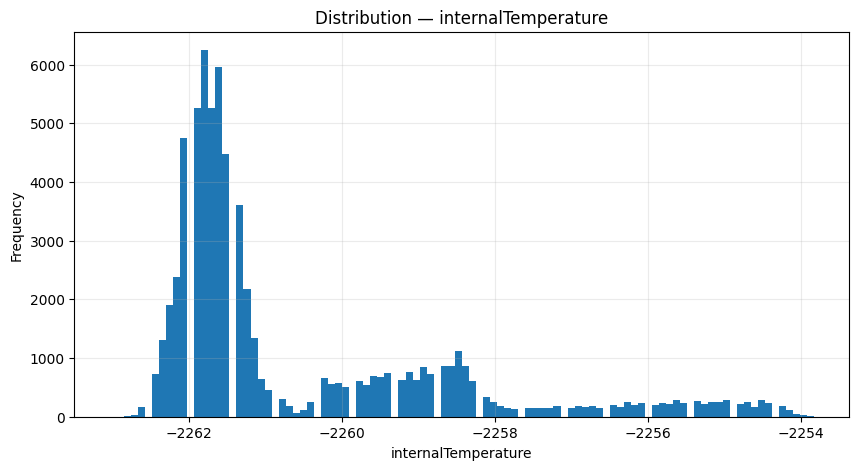

In [8]:
for signal in ENGINEERING_FIELDS[:-1]:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(
        aging[signal].dropna(),
        bins=100
    )
    ax.set_title(f"Distribution — {signal}")
    ax.set_xlabel(signal)
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.25)
    plt.show()

## 6. Robust statistics

Means can be strongly influenced by switching spikes.

We therefore compare:
- mean
- median
- standard deviation
- interquartile range
- lower/upper quantiles

This helps us distinguish a stable signal with occasional spikes from a genuinely changing baseline.

In [9]:
robust_rows = []

for signal in ENGINEERING_FIELDS[:-1]:
    s = pd.to_numeric(aging[signal], errors="coerce").dropna()

    robust_rows.append({
        "signal": signal,
        "mean": s.mean(),
        "median": s.median(),
        "std": s.std(),
        "q01": s.quantile(0.01),
        "q05": s.quantile(0.05),
        "q25": s.quantile(0.25),
        "q75": s.quantile(0.75),
        "q95": s.quantile(0.95),
        "q99": s.quantile(0.99),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
    })

robust_stats = pd.DataFrame(robust_rows)
display(robust_stats)

robust_stats.to_csv(
    PROCESSED / "eda_robust_statistics.csv",
    index=False
)

,signal,mean,median,std,q01,q05,q25,q75,q95,q99,IQR
0,supplyVoltage,4.707065,4.936846,1.089938,2.449125,2.460287,3.944827,5.427972,5.923283,5.927469,1.483145
1,node1Voltage,4.704696,4.935600,1.089821,2.445928,2.458363,3.942218,5.426074,5.920693,5.926219,1.483856
2,node2Voltage,4.373966,4.912348,1.104186,1.925936,2.115440,3.594121,5.119834,5.612267,5.924879,1.525712
3,collectorEmitterCurrent,0.106224,0.091770,0.038150,0.041464,0.076459,0.085208,0.133326,0.155198,0.205503,0.048118
4,heatSinkTemperature,719.129660,719.171676,0.101922,718.815463,718.884730,719.078999,719.194862,719.227335,719.278391,0.115863
5,packageTemperature,220.001322,254.416800,63.963280,59.651783,97.282307,175.703674,269.116877,278.571562,280.821907,93.413203
6,internalTemperature,-2260.580357,-2261.473330,1.977514,-2262.474411,-2262.251879,-2261.806934,-2259.584582,-2255.704886,-2254.488002,2.222352


## 7. Aging trends

We plot each signal against **elapsed device time**, not event index.

This is critical because files have different sampling densities and durations.

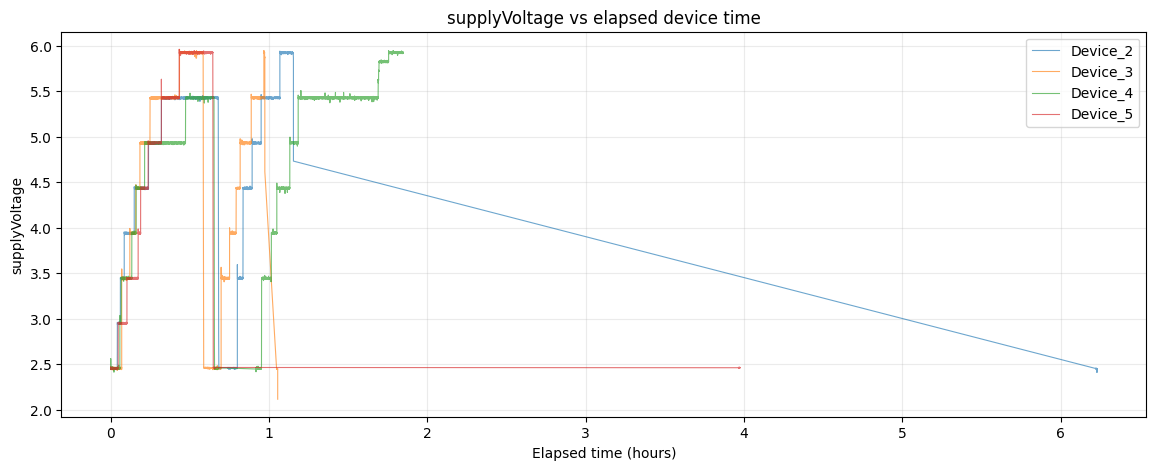

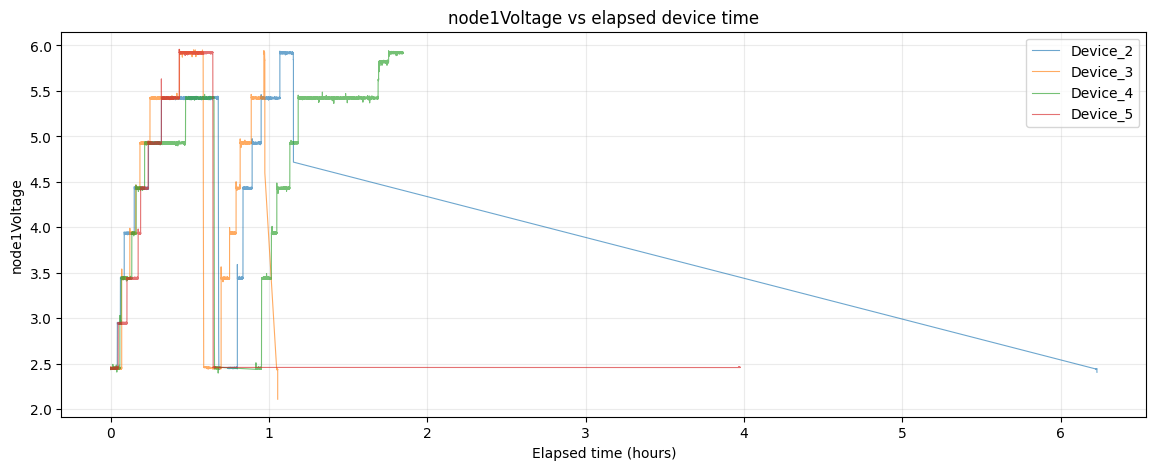

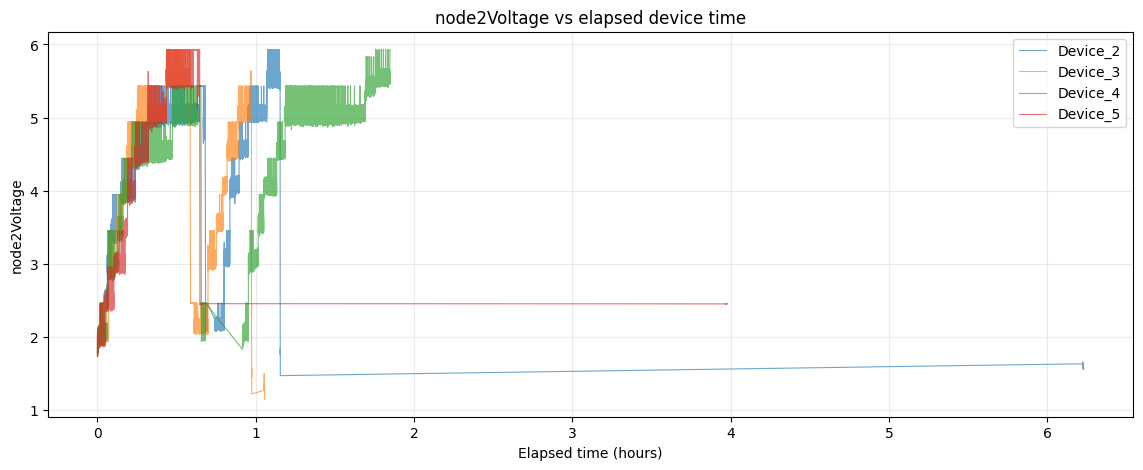

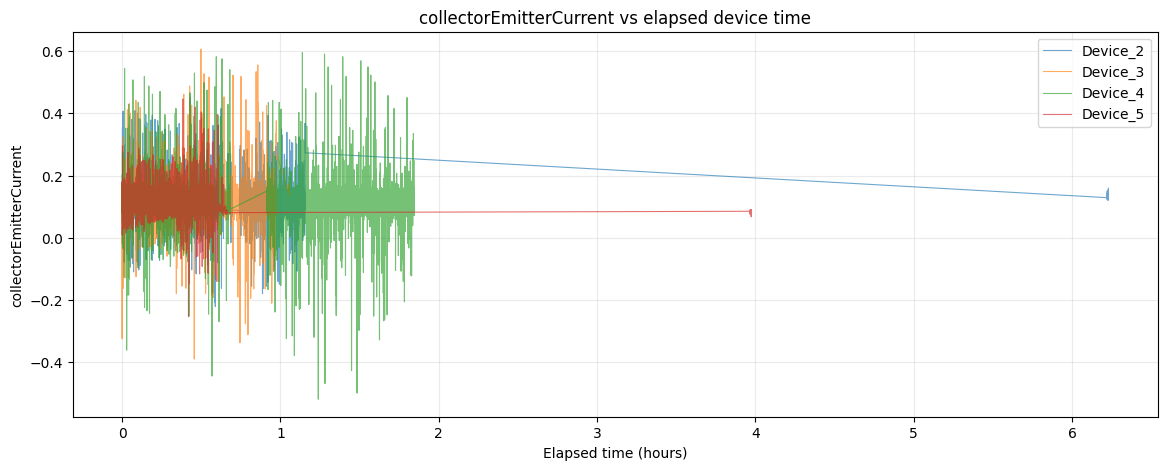

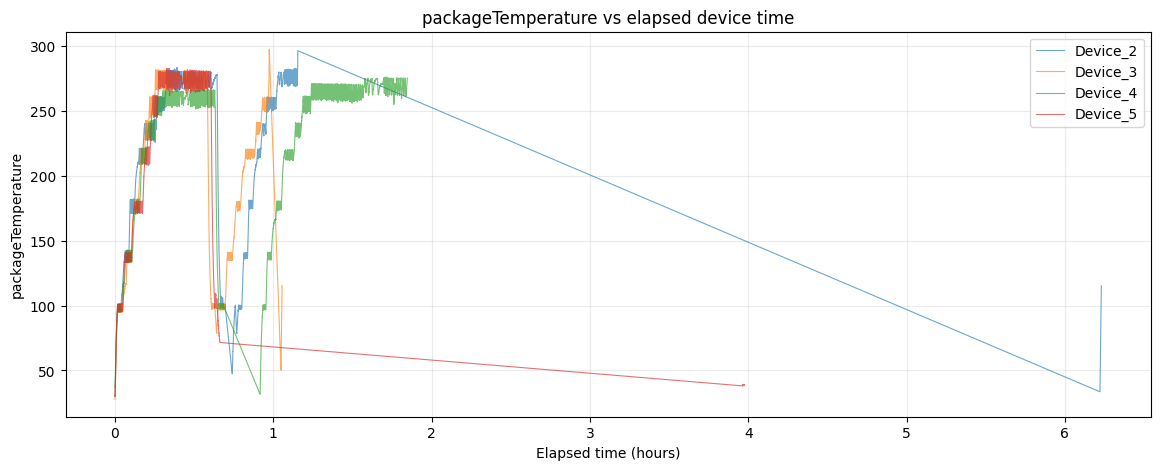

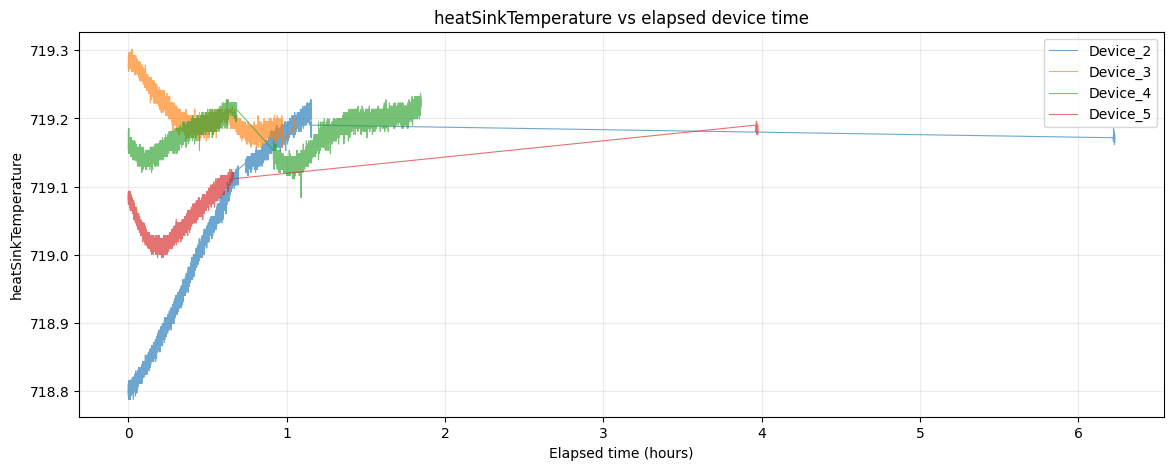

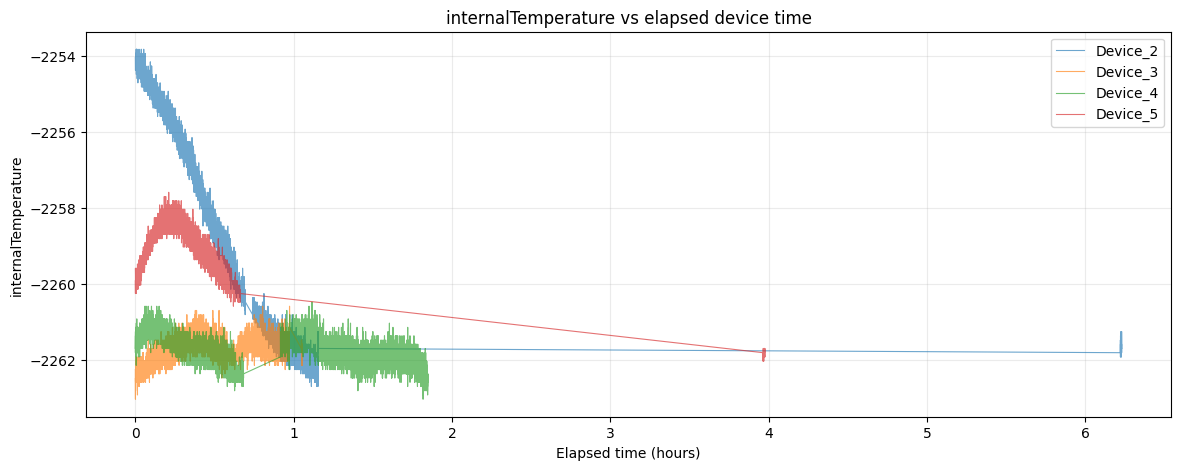

In [10]:
plot_signals = [
    "supplyVoltage",
    "node1Voltage",
    "node2Voltage",
    "collectorEmitterCurrent",
    "packageTemperature",
    "heatSinkTemperature",
    "internalTemperature",
]

for signal in plot_signals:
    fig, ax = plt.subplots(figsize=(14, 5))

    for device_id, group in aging.groupby("device_id"):
        ax.plot(
            group["elapsed_hours"],
            group[signal],
            linewidth=0.8,
            alpha=0.65,
            label=device_id
        )

    ax.set_title(f"{signal} vs elapsed device time")
    ax.set_xlabel("Elapsed time (hours)")
    ax.set_ylabel(signal)
    ax.grid(alpha=0.25)
    ax.legend()
    plt.show()

## 8. Rolling-window behavior

Raw records can be noisy. We calculate a rolling median for each device.

This is **EDA only**: the rolling statistics are not yet the final ML features.

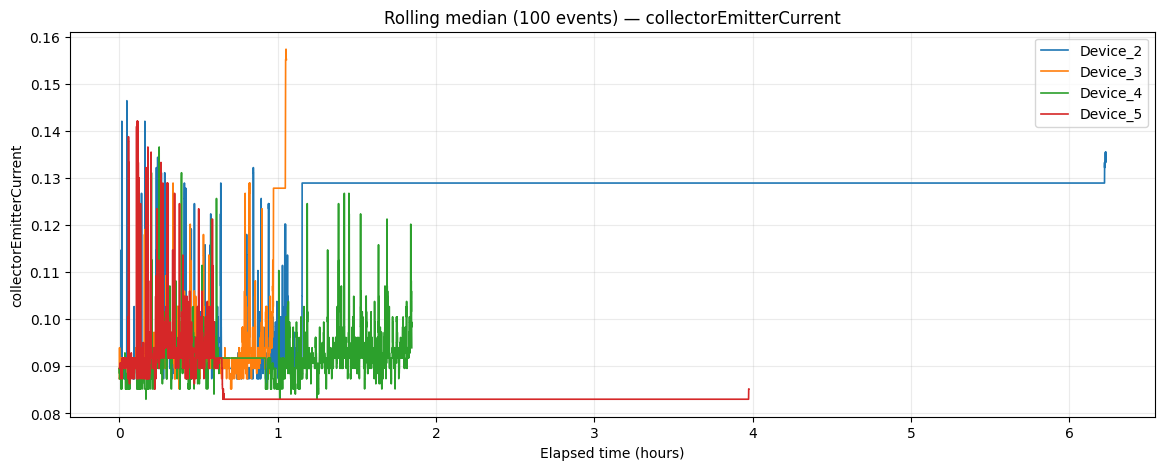

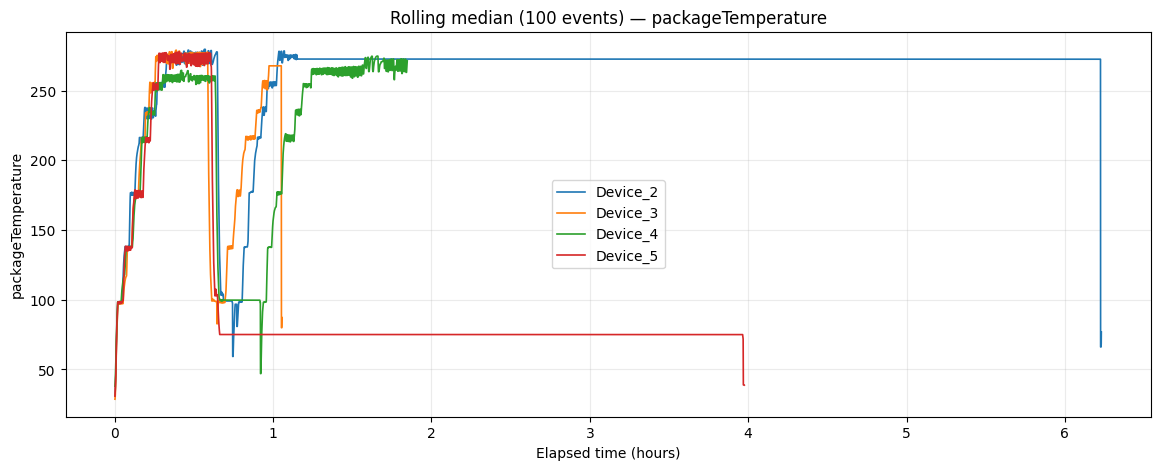

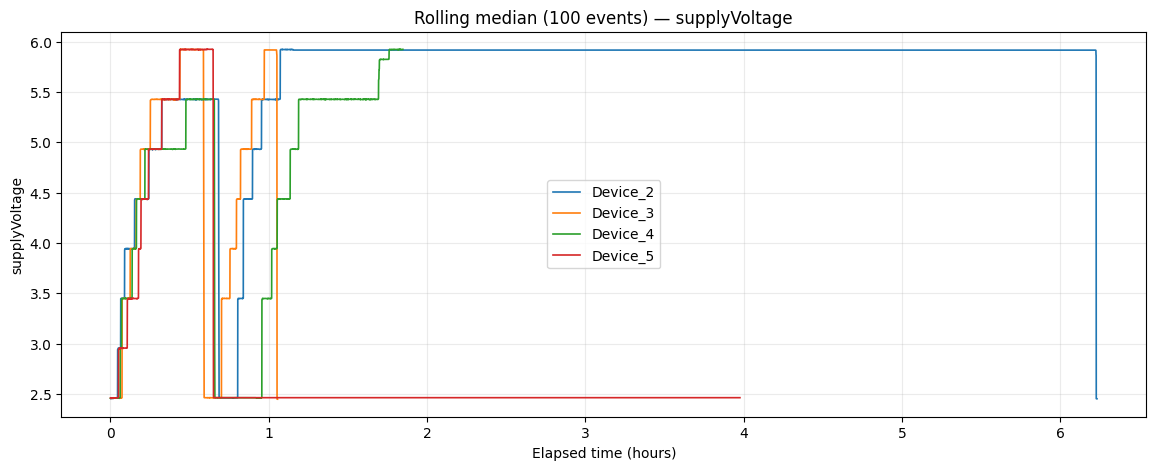

In [11]:
ROLLING_EVENTS = 100

signals_for_rolling = [
    "collectorEmitterCurrent",
    "packageTemperature",
    "supplyVoltage"
]

for signal in signals_for_rolling:
    fig, ax = plt.subplots(figsize=(14, 5))

    for device_id, group in aging.groupby("device_id"):
        group = group.sort_values("elapsed_seconds").copy()

        rolling = (
            group[signal]
            .rolling(ROLLING_EVENTS, min_periods=20)
            .median()
        )

        ax.plot(
            group["elapsed_hours"],
            rolling,
            linewidth=1.2,
            label=device_id
        )

    ax.set_title(
        f"Rolling median ({ROLLING_EVENTS} events) — {signal}"
    )
    ax.set_xlabel("Elapsed time (hours)")
    ax.set_ylabel(signal)
    ax.grid(alpha=0.25)
    ax.legend()
    plt.show()

## 9. Correlation analysis

We inspect relationships between signals.

Correlation alone does not prove a physical relationship, but it helps identify:
- redundant variables
- strongly coupled signals
- variables worth investigating together

,supplyVoltage,node1Voltage,node2Voltage,collectorEmitterCurrent,heatSinkTemperature,packageTemperature,internalTemperature
supplyVoltage,1.000,1.000,0.985,-0.002,0.131,0.909,-0.115
node1Voltage,1.000,1.000,0.985,-0.002,0.131,0.909,-0.115
node2Voltage,0.985,0.985,1.000,-0.034,0.137,0.885,-0.122
collectorEmitterCurrent,-0.002,-0.002,-0.034,1.000,-0.046,0.014,0.057
heatSinkTemperature,0.131,0.131,0.137,-0.046,1.000,0.065,-0.981
packageTemperature,0.909,0.909,0.885,0.014,0.065,1.000,-0.047
internalTemperature,-0.115,-0.115,-0.122,0.057,-0.981,-0.047,1.000


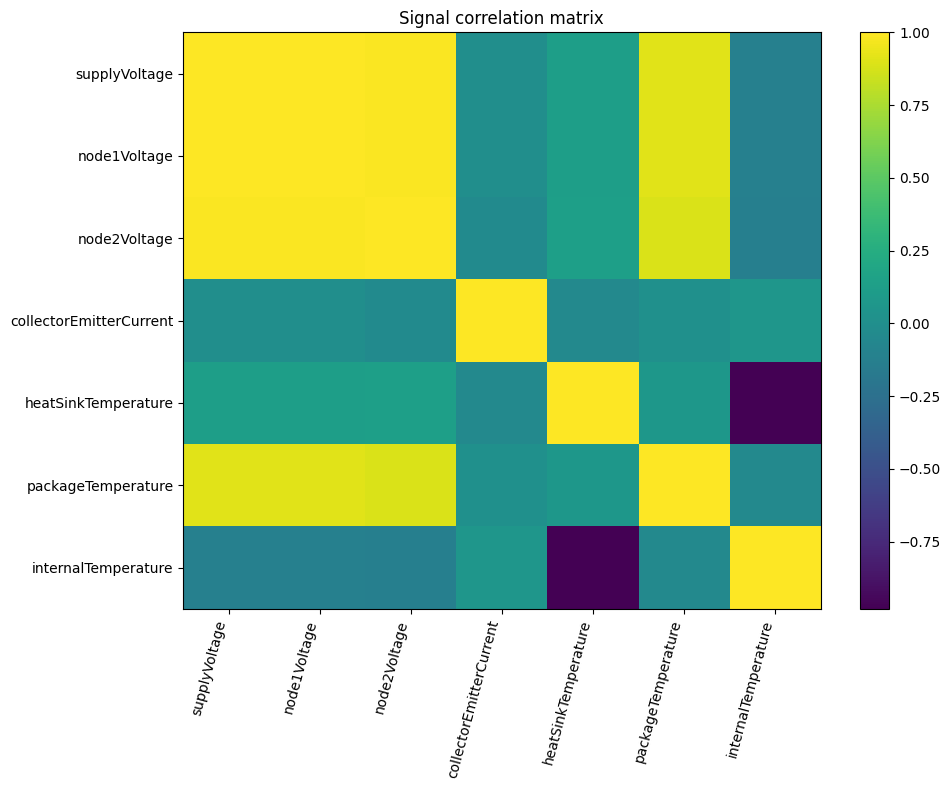

In [12]:
corr = aging[
    ENGINEERING_FIELDS[:-1]
].corr(numeric_only=True)

display(corr.round(3))

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr.values, aspect="auto")
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.index)))
ax.set_xticklabels(corr.columns, rotation=75, ha="right")
ax.set_yticklabels(corr.index)
ax.set_title("Signal correlation matrix")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 10. File-role comparison

The dataset contains `main`, `b`, and `check` files.

We will NOT assume what these roles mean yet. We compare their observed measurement ranges so that we can later use the experiment documentation to interpret them.

In [13]:
role_summary = (
    aging
    .groupby(["device_id", "file_role"])
    [ENGINEERING_FIELDS[:-1]]
    .agg(["count", "mean", "std", "min", "max"])
)

display(role_summary)

supplyVoltage                                         node1Voltage                                         node2Voltage                                          \
                            count      mean       std       min       max        count      mean       std       min       max        count      mean       std       min       max   
device_id file_role                                                                                                                                                                   
Device_2  b                  6434  4.764506  1.123855  2.442149  5.938631         6434  4.762269  1.123582  2.444546  5.937272         6434  4.440331  1.116732  1.473617  5.929028   
          check               116  2.450256  0.003972  2.411454  2.454706          116  2.444904  0.003874  2.407243  2.448691          116  1.602652  0.020246  1.560761  1.661738   
          main              10977  4.724532  0.937927  2.439359  5.448900        10977  4.722203  0.937914  2.437638  5.442653        10977  4.390532  0.964469  1.737816  5.435212   
Device_3  b                  5238  4.245228  1.070102  2.437964  5.945607         5238  4.242840  1.069742  2.443165  5.942799         5238  3.913103  1.050692  1.223251  5.646848   
          check               112  2.443644  0.031460  2.114267  2.451916          112  2.436540  0.031030  2.111577  2.444546          112  1.332058  0.034574  1.151323  1.504049   
          main               9836  4.660813  1.259632  2.430987  5.956769         9836  4.658450  1.259316  2.437638  5.952470         9836  4.331480  1.251708  1.726750  5.930412   
Device_4  b                 14607  5.078078  0.842648  2.415640  5.945607        14607  5.075625  0.842501  2.440402  5.941417        14607  4.737276  0.855195  1.833259  5.934561   
          main              10770  4.494198  0.990161  2.411454  5.476805        10770  4.491826  0.990139  2.398953  5.461996        10770  4.162476  1.010095  1.750265  5.436595   
Device_5  check               161  2.461925  0.001320  2.457497  2.464473          161  2.461598  0.001037  2.459744  2.465271          161  2.454161  0.002191  2.443267  2.458483   
          main              10510  4.713029  1.223611  2.443545  5.959560        10510  4.710712  1.223645  2.437638  5.957996        10510  4.389683  1.258574  1.735049  5.931795   

                    collectorEmitterCurrent                                         heatSinkTemperature                                               packageTemperature                         \
                                      count      mean       std       min       max               count        mean       std         min         max              count        mean        std   
device_id file_role                                                                                                                                                                               
Device_2  b                            6434  0.106338  0.036234 -0.179441  0.393600                6434  719.171993  0.024465  719.116056  719.227335               6434  214.632264  65.970333   
          check                         116  0.136418  0.007772  0.120203  0.159572                 116  719.172955  0.004306  719.162403  719.185587                116   72.011154  25.192249   
          main                        10977  0.107798  0.036707 -0.220997  0.450467               10977  718.953336  0.097172  718.787773  719.129957              10977  225.553577  63.209671   
Device_3  b                            5238  0.106228  0.040816 -0.336918  0.555452                5238  719.184155  0.008481  719.157767  719.218056               5238  184.176612  55.064569   
          check                         112  0.156565  0.007807  0.137700  0.174882                 112  719.191135  0.004482  719.180950  719.199500                112   83.231542  19.677660   
          main                         9836  0.107370  0.038073 -0.389410  0.605

# STOP POINT

Do not train the anomaly model yet.

We are specifically looking for answers to:

1. Are any signals structurally unusable?
2. Are the unusual temperature scales documented/expected or a conversion issue?
3. Are `main`, `b`, and `check` different stages of the same device experiment?
4. Are there meaningful monotonic/drifting trends?
5. Are operating conditions changing during aging?
6. Which signals should be used directly and which need transformation?
7. Should SMU characterization be combined with aging measurements or treated as a separate baseline dataset?

The next stage will be **experiment-aware cleaning + time-window/cycle segmentation + feature engineering**.